# 03 · Entrenamiento de `dinov2_partial` con split re-balanceado (Massachusetts Roads)

Copia del notebook 02 (mismo modelo, pérdida, métricas y semilla) con dos cambios:

1. **Condición fija:** `CONDITION = "dinov2_partial"` (últimos `N_UNFREEZE` bloques de DINOv2 + `norm` descongelados, LR bajo). `RUN_TEARDOWN = False`: el Bloque A ya se corrió en el notebook 02.
2. **Split re-balanceado:** el original de Massachusetts es 1108 / 14 / 49 tiles (train / val / test), lo que da una validación de solo 14 tiles. Aquí se juntan los 1171 tiles y se re-parten **por tile** (no por recorte, para evitar fuga entre splits) con `SPLIT_FRACS = (0.70, 0.15, 0.15)` y una semilla fija (`SPLIT_SEED`).

**Cómo ejecutar en Kaggle:** GPU T4, Internet On, Add Input → *Massachusetts Roads Dataset* (`balraj98/massachusetts-roads-dataset`). Ejecutar todo (Restart & Run All).

**Aviso de comparabilidad:** los resultados de este notebook **no son comparables** con las corridas de `resnet50` y `dinov2_frozen` hechas con el split original. Para comparar ablaciones hay que re-entrenarlas con este mismo split (cambiar solo `CONDITION`).


## 0. Instalación de dependencias
Kaggle ya trae `torch`, `torchvision`, `scikit-learn` y `scipy`. DINOv2 se obtiene con `torch.hub` (no requiere pip). Se protege la instalación por si algún módulo faltara.

In [1]:
import importlib.util
import subprocess
import sys

for pkg, mod in [("scikit-learn", "sklearn"), ("scipy", "scipy"), ("tqdm", "tqdm"), ("pandas", "pandas")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
print("Dependencias listas.")

Dependencias listas.


## 1. CONFIG (única celda de configuración)
`DINO_INPUT = 518`: DINOv2 usa parches de 14 px y 512 no es divisible por 14 (512/14 = 36.57). Se redimensiona la imagen a **518 = 37 × 14** (rejilla de 37 × 37 = 1369 tokens), y los mapas de características se reescalan a las resoluciones de la entrada de 512 para el decodificador; la salida final queda en 512 × 512 y la pérdida/métricas se calculan a 512.

In [2]:
# ----------------------------- Qué ejecutar -----------------------------
RUN_TEARDOWN = False           # Bloque A ya ejecutado en el notebook 02
RUN_TRAINING = True            # Bloque B
RUN_LABEL_AUDIT = False        # Sección opcional: auditoría de etiquetas basada en un modelo (ver Bloque B)

DATASET = "massachusetts"      # "massachusetts" | "overture"
CONDITION = "dinov2_partial"   # "resnet50" | "dinov2_frozen" | "dinov2_partial"

# ----------------------------- Modelos -----------------------------
RESNET_WEIGHTS = "imagenet"    # "imagenet" (IMAGENET1K_V2) | "scratch"
DINO_VARIANT = "dinov2_vits14" # ViT-S/14 (21 M parámetros): cabe en T4 con batch 8 y AMP
DINO_INPUT = 518               # 37 x 14; 512 no es divisible por 14
N_UNFREEZE = 2                 # bloques finales a descongelar en dinov2_partial
DECODER_CH = (64, 128, 256, 512)   # canales del decodificador (strides 4, 8, 16, 32)
CROP = 512

# ----------------------------- Entrenamiento -----------------------------
EPOCHS = 20
BATCH_SIZE = 8                 # si hay OOM, bajar a 4
LR_DECODER = 3e-4              # decodificador + adaptador/neck (siempre desde cero)
LR_BACKBONE = 1e-4             # ResNet-50 completo (fine-tuning)
LR_DINO_TAIL = 1e-5            # cola de DINOv2 (muy bajo)
WEIGHT_DECAY = 1e-4
WARMUP_FRAC = 0.05             # fracción de pasos con warmup lineal
GRAD_CLIP = 1.0
AMP = True                     # precisión mixta FP16
NUM_WORKERS = 2
THRESHOLD = 0.5                # umbral de probabilidad
RELAX_RHO = 3                  # tolerancia (px) de la métrica relajada
TRAIN_CROPS_PER_TILE = 3       # Massachusetts: recortes aleatorios por tile y por época (3 compensa el train más chico: ~820 tiles)
MAX_TRAIN_STEPS_PER_EPOCH = None   # tope opcional de pasos por época (p. ej. 150 para pruebas rápidas)
SEED = 42

# ----------------------------- Datos -----------------------------
MASS_ROOT = None               # None = descubrir bajo /kaggle/input
SPLIT_FRACS = (0.70, 0.15, 0.15)   # train / val / test, a nivel de tile (Massachusetts)
SPLIT_SEED = 42                # semilla del re-split (independiente de SEED para poder repetirlo igual en otras condiciones)
SPLIT_TAG = "resplit"          # sufijo en nombres de salida para no pisar resultados del split original
OVERTURE_ROOT = None           # None = descubrir carpeta con patches.csv bajo /kaggle/input
USE_ALIGNED_MASKS = False      # Overture: usar masks_aligned/ (si el notebook 01 las generó)
MASS_BLANK_THR = 0.25          # se rechazan recortes con >25 % de píxeles blancos (sin datos)
MASS_GRID_STARTS = (0, 494, 988)   # inicios de la rejilla 3x3 de recortes de 512 sobre 1500 px

# ----------------------------- Teardown -----------------------------
TEARDOWN_CONDITIONS = ["resnet50", "dinov2_frozen", "dinov2_partial"]
LAT_WARMUP, LAT_ITERS = 20, 100
LAT_BATCHES = (1, 8)
VRAM_BATCHES_TRAIN = (4, 8)
ERF_N_IMAGES = 8
PCA_N_IMAGES = 16
PCA_ROAD_FRACS = (0.5, 0.25)   # umbral de fracción de vía por token (el principal es 0.5)

# ----------------------------- Auditoría de etiquetas (opcional) -----------------------------
AUDIT_CONDITION = "resnet50"   # condición del checkpoint entrenado en Massachusetts
AUDIT_CKPT = None              # ruta al .pt; None = buscar massachusetts_{AUDIT_CONDITION}.pt
AUDIT_N_PATCHES = 200
AUDIT_SHIFT_R = 12
AUDIT_CONF_MIN = 2.0

# ----------------------------- Rutas de salida -----------------------------
WORK = "/kaggle/working"
RESULTS_DIR = f"{WORK}/results"
FIG_DIR = f"{WORK}/figures"
CKPT_DIR = f"{WORK}/checkpoints"

In [3]:
import os, sys, json, math, time, glob, random, copy, contextlib, functools
os.environ.setdefault("XFORMERS_DISABLED", "1")   # atención explícita (medible por FlopCounter y hooks)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


def seed_everything(seed):
    """Fija todas las semillas relevantes para reproducibilidad."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for d in [RESULTS_DIR, FIG_DIR, CKPT_DIR]:
    os.makedirs(d, exist_ok=True)
assert CONDITION in ("resnet50", "dinov2_frozen", "dinov2_partial"), CONDITION
assert DATASET in ("massachusetts", "overture"), DATASET

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()


def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if math.isnan(float(o)) else float(o)
    return o


def denorm(x):
    """Tensor normalizado (3,H,W) -> imagen float [0,1] (H,W,3)."""
    return (x.cpu() * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()


print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), f"| VRAM total: {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda
GPU: Tesla T4 | VRAM total: 14.6 GiB


## 2. Descubrimiento de datos y datasets
Las rutas se buscan con *glob* bajo `/kaggle/input` (sin depender del slug del dataset); si no se encuentran, el error indica qué agregar como input.

- **`MassachusettsRoads`:** recortes de 512 × 512 *al vuelo* desde tiles de 1500 × 1500. Entrenamiento: recorte aleatorio, rechazando los que tengan más de 25 % de píxeles blancos (sin datos). Validación/test: rejilla determinista 3 × 3 (inicios 0, 494, 988), descartando recortes mayormente blancos, para evaluaciones reproducibles.
- **`OverturePatches`:** lee `patches.csv` y usa su columna `split` (split espacial por bloques del notebook 01).
- **Aumentos (solo train):** volteos, rot90 y *color jitter* leve (brillo/contraste/saturación ±15 %), implementados con numpy; normalización ImageNet para ambos backbones. Los aumentos geométricos se aplican igual a imagen y máscara.

In [4]:
def find_massachusetts():
    """Raíz que contiene train/val/test y sus *_labels bajo /kaggle/input."""
    for c in glob.glob("/kaggle/input/**/train_labels", recursive=True):
        root = os.path.dirname(c)
        if all(os.path.isdir(f"{root}/{d}") for d in ["train", "val", "test", "train_labels", "val_labels", "test_labels"]):
            return root
    raise FileNotFoundError("No se encontró Massachusetts Roads en /kaggle/input. Usa 'Add Input' y agrega el dataset "
                            "(p. ej. balraj98/massachusetts-roads-dataset), o fija MASS_ROOT en CONFIG.")


def find_overture_root():
    """Carpeta overture_lima/ (con patches.csv, images/ y masks/) bajo /kaggle/input."""
    for c in glob.glob("/kaggle/input/**/patches.csv", recursive=True):
        root = os.path.dirname(c)
        if os.path.isdir(f"{root}/images") and os.path.isdir(f"{root}/masks"):
            return root
    raise FileNotFoundError("No se encontró overture_lima/ (patches.csv + images/ + masks/) en /kaggle/input. "
                            "Genera el dataset con el notebook 01, guárdalo como Kaggle Dataset y agrégalo como input.")


def list_pairs(root, split):
    exts = (".tif", ".tiff", ".png")
    imgs = {os.path.splitext(f)[0]: f"{root}/{split}/{f}" for f in os.listdir(f"{root}/{split}") if f.lower().endswith(exts)}
    lbls = {os.path.splitext(f)[0]: f"{root}/{split}_labels/{f}" for f in os.listdir(f"{root}/{split}_labels") if f.lower().endswith(exts)}
    return [(k, imgs[k], lbls[k]) for k in sorted(set(imgs) & set(lbls))]


def list_pairs_resplit(root, split):
    """Junta train+val+test originales y re-parte POR TILE con SPLIT_FRACS y SPLIT_SEED (determinista)."""
    pool = []
    for s in ("train", "val", "test"):
        pool += list_pairs(root, s)
    pool = sorted(pool, key=lambda p: p[0])
    assert len({p[0] for p in pool}) == len(pool), "Nombres de tile duplicados entre splits"
    perm = np.random.RandomState(SPLIT_SEED).permutation(len(pool))
    n_tr = int(round(SPLIT_FRACS[0] * len(pool)))
    n_va = int(round(SPLIT_FRACS[1] * len(pool)))
    idx = {"train": perm[:n_tr], "val": perm[n_tr:n_tr + n_va], "test": perm[n_tr + n_va:]}[split]
    return [pool[i] for i in sorted(idx)]


@functools.lru_cache(maxsize=16)
def read_rgb(path):
    return np.array(Image.open(path).convert("RGB"))


@functools.lru_cache(maxsize=16)
def read_label(path):
    return (np.array(Image.open(path).convert("L")) > 127).astype(np.uint8)


def blank_fraction(rgb):
    return float((rgb.min(axis=2) >= 250).mean())


def augment(img, mask):
    """Volteos, rot90 y color jitter leve. img uint8 (H,W,3), mask uint8 (H,W)."""
    if np.random.rand() < 0.5:
        img, mask = img[:, ::-1], mask[:, ::-1]
    if np.random.rand() < 0.5:
        img, mask = img[::-1], mask[::-1]
    k = np.random.randint(4)
    img, mask = np.rot90(img, k), np.rot90(mask, k)
    x = img.astype(np.float32) / 255.0
    x = x * (1 + np.random.uniform(-0.15, 0.15))                       # brillo
    m = x.mean()
    x = (x - m) * (1 + np.random.uniform(-0.15, 0.15)) + m             # contraste
    g = x.mean(axis=2, keepdims=True)
    x = (x - g) * (1 + np.random.uniform(-0.15, 0.15)) + g             # saturación
    return np.clip(x, 0, 1), np.ascontiguousarray(mask)


def to_tensors(img, mask):
    """img: uint8 o float[0,1] (H,W,3); mask (H,W) -> tensores normalizados (3,H,W) y (1,H,W)."""
    x = img.astype(np.float32) / 255.0 if img.dtype == np.uint8 else img.astype(np.float32)
    x = (torch.from_numpy(np.ascontiguousarray(x)).permute(2, 0, 1) - MEAN) / STD
    return x, torch.from_numpy(np.ascontiguousarray(mask)).float().unsqueeze(0)


def worker_init(worker_id):
    s = (torch.initial_seed() + worker_id) % 2 ** 32
    np.random.seed(s)
    random.seed(s)


class MassachusettsRoads(Dataset):
    def __init__(self, root, split):
        self.split, self.train = split, split == "train"
        self.pairs = list_pairs_resplit(root, split)
        if not self.pairs:
            raise FileNotFoundError(f"Sin pares imagen/etiqueta en {root}/{split}")
        if self.train:
            self.index = [(i, None, None) for i in range(len(self.pairs)) for _ in range(TRAIN_CROPS_PER_TILE)]
        else:   # rejilla determinista 3x3; se descartan recortes mayormente blancos
            self.index = []
            for i, (_, ip, _) in enumerate(self.pairs):
                rgb = read_rgb(ip)
                for oy in MASS_GRID_STARTS:
                    for ox in MASS_GRID_STARTS:
                        if blank_fraction(rgb[oy:oy + CROP, ox:ox + CROP]) <= MASS_BLANK_THR:
                            self.index.append((i, oy, ox))

    def __len__(self):
        return len(self.index)

    def __getitem__(self, k):
        i, oy, ox = self.index[k]
        _, ip, lp = self.pairs[i]
        rgb, lab = read_rgb(ip), read_label(lp)
        if self.train:
            H, W = lab.shape
            for _ in range(10):
                oy, ox = np.random.randint(0, H - CROP + 1), np.random.randint(0, W - CROP + 1)
                if blank_fraction(rgb[oy:oy + CROP, ox:ox + CROP]) <= MASS_BLANK_THR:
                    break
        img, m = rgb[oy:oy + CROP, ox:ox + CROP], lab[oy:oy + CROP, ox:ox + CROP]
        if self.train:
            img, m = augment(img, m)
        return to_tensors(img, m)


class OverturePatches(Dataset):
    def __init__(self, root, split):
        df = pd.read_csv(f"{root}/patches.csv")
        self.df = df[df["split"] == split].reset_index(drop=True)
        self.root, self.train = root, split == "train"
        mdir = "masks_aligned" if (USE_ALIGNED_MASKS and os.path.isdir(f"{root}/masks_aligned")) else "masks"
        self.mdir = mdir
        if len(self.df) == 0:
            raise ValueError(f"patches.csv no tiene parches en el split '{split}'")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, k):
        pid = self.df.loc[k, "id"]
        img = np.array(Image.open(f"{self.root}/images/{pid}.png").convert("RGB"))
        m = (np.array(Image.open(f"{self.root}/{self.mdir}/{pid}.png").convert("L")) > 127).astype(np.uint8)
        if self.train:
            img, m = augment(img, m)
        return to_tensors(img, m)


def build_dataset(name, split):
    if name == "massachusetts":
        return MassachusettsRoads(MASS_ROOT or find_massachusetts(), split)
    return OverturePatches(OVERTURE_ROOT or find_overture_root(), split)


def make_loader(ds, shuffle, drop_last=False, batch_size=None):
    return DataLoader(ds, batch_size=batch_size or BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS, drop_last=drop_last,
                      pin_memory=DEVICE.type == "cuda", worker_init_fn=worker_init, persistent_workers=NUM_WORKERS > 0,
                      generator=torch.Generator().manual_seed(SEED))


def pick_samples(ds, n, min_ratio=0.03):
    """Primeras n muestras espaciadas con fracción de vía >= min_ratio (para figuras del teardown)."""
    xs, ys = [], []
    step = max(1, len(ds) // (4 * n))
    for k in range(0, len(ds), step):
        x, y = ds[k]
        if y.mean() >= min_ratio:
            xs.append(x); ys.append(y)
        if len(xs) == n:
            break
    if not xs:
        raise RuntimeError("No se hallaron muestras con vía suficiente para las figuras del teardown.")
    return torch.stack(xs), torch.stack(ys)


print("Funciones de datos definidas.")

Funciones de datos definidas.


## 3. Modelos: encoders, adaptadores y decodificador común
Diseño que garantiza un **decodificador idéntico**:

- `ResNet50Encoder` devuelve 4 mapas: layer1 (256 ch, /4), layer2 (512, /8), layer3 (1024, /16), layer4 (2048, /32).
- `DinoV2Encoder` devuelve 4 mapas de 384 ch en rejilla 37 × 37 (bloques 2, 5, 8, 11 de 12, calculados de forma genérica). Como ViT no tiene jerarquía espacial, un **neck de pirámide simple** (estilo ViTDet; liviano y entrenable) reescala cada mapa a los strides 4/8/16/32 de la entrada (128, 64, 32, 16) con interpolación bilineal + conv 1×1 + BN + ReLU.
- Un **adaptador de canales** por encoder (conv 1×1 + BN + ReLU) lleva todo a `DECODER_CH = (64, 128, 256, 512)`. El decodificador solo ve esos 4 mapas: es literalmente la misma clase con el mismo número de parámetros (se verifica con `assert`).
- **Nota de equidad:** el neck de DINOv2 añade un pequeño costo entrenable que ResNet no tiene (su adaptador es más liviano); se reporta en la tabla de parámetros del teardown.
- **Congelado:** `frozen` → todo el backbone con `requires_grad=False` y en `eval()`; `partial` → solo los últimos `N_UNFREEZE` bloques y la `norm` final. Como las features de los bloques 2, 5 y 8 no dependen de los bloques 10–11, descongelar la cola solo modifica la salida del bloque 11 (el último mapa) y, vía `norm` compartida, la normalización de los demás.

In [5]:
class ConvBNReLU(nn.Sequential):
    def __init__(self, cin, cout, k=3):
        super().__init__(nn.Conv2d(cin, cout, k, padding=k // 2, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))


class ResNet50Encoder(nn.Module):
    """ResNet-50 de torchvision que devuelve [layer1 (/4), layer2 (/8), layer3 (/16), layer4 (/32)]."""
    out_channels = (256, 512, 1024, 2048)

    def __init__(self, weights="imagenet"):
        super().__init__()
        w = torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if weights == "imagenet" else None
        m = torchvision.models.resnet50(weights=w)
        self.stem = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = m.layer1, m.layer2, m.layer3, m.layer4

    def forward(self, x):
        x = self.stem(x)
        f1 = self.layer1(x)
        f2 = self.layer2(f1)
        f3 = self.layer3(f2)
        f4 = self.layer4(f3)
        return [f1, f2, f3, f4]


class ResNetAdapter(nn.Module):
    """Conv 1x1 + BN + ReLU por nivel: lleva los canales de ResNet a DECODER_CH."""

    def __init__(self, in_chs, out_chs):
        super().__init__()
        self.proj = nn.ModuleList([ConvBNReLU(i, o, k=1) for i, o in zip(in_chs, out_chs)])

    def forward(self, feats, size):
        return [p(f) for p, f in zip(self.proj, feats)]


class DinoV2Encoder(nn.Module):
    """DINOv2 (torch.hub) sin cabeza de clasificación. mode: 'frozen' | 'partial'."""

    def __init__(self, variant, mode, input_size=518, n_unfreeze=2):
        super().__init__()
        assert mode in ("frozen", "partial")
        self.mode, self.input_size = mode, input_size
        self.backbone = torch.hub.load("facebookresearch/dinov2", variant, trust_repo=True)
        self.embed_dim = self.backbone.embed_dim
        self.n_blocks = len(self.backbone.blocks)
        # índices equiespaciados terminando en el último bloque (12 bloques -> [2, 5, 8, 11])
        self.layer_ids = [(i + 1) * self.n_blocks // 4 - 1 for i in range(4)]
        for p in self.backbone.parameters():
            p.requires_grad = False
        if mode == "partial":
            for blk in self.backbone.blocks[-n_unfreeze:]:
                for p in blk.parameters():
                    p.requires_grad = True
            for p in self.backbone.norm.parameters():
                p.requires_grad = True

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()      # DINOv2 no tiene BN/dropout activo; se mantiene en eval siempre
        return self

    def forward(self, x):
        x = F.interpolate(x, size=(self.input_size, self.input_size), mode="bilinear", align_corners=False)
        ctx = torch.no_grad() if self.mode == "frozen" else contextlib.nullcontext()
        with ctx:
            feats = self.backbone.get_intermediate_layers(x, n=self.layer_ids, reshape=True, norm=True)
        return list(feats)      # 4 x (B, D, 37, 37)


class DinoPyramidNeck(nn.Module):
    """Pirámide simple (estilo ViTDet): reescala a strides 4/8/16/32 + conv 1x1 + BN + ReLU."""

    def __init__(self, embed_dim, out_chs, strides=(4, 8, 16, 32)):
        super().__init__()
        self.strides = strides
        self.proj = nn.ModuleList([ConvBNReLU(embed_dim, o, k=1) for o in out_chs])

    def forward(self, feats, size):
        H, W = size
        outs = []
        for f, p, s in zip(feats, self.proj, self.strides):
            f = F.interpolate(f, size=(H // s, W // s), mode="bilinear", align_corners=False)
            outs.append(p(f))
        return outs


class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(ConvBNReLU(cin, cout, 3), ConvBNReLU(cout, cout, 3))


class UNetDecoder(nn.Module):
    """Decodificador U-Net: de /32 a /4 (upsample x2 + skip + 2 convs) y luego x4 hasta la entrada -> 1 logit."""

    def __init__(self, chs=DECODER_CH):
        super().__init__()
        c4, c8, c16, c32 = chs
        self.up16 = DoubleConv(c32 + c16, c16)
        self.up8 = DoubleConv(c16 + c8, c8)
        self.up4 = DoubleConv(c8 + c4, c4)
        self.head = nn.Conv2d(c4, 1, kernel_size=1)

    def forward(self, feats, size):
        f4, f8, f16, f32 = feats
        x = self.up16(torch.cat([F.interpolate(f32, size=f16.shape[-2:], mode="bilinear", align_corners=False), f16], 1))
        x = self.up8(torch.cat([F.interpolate(x, size=f8.shape[-2:], mode="bilinear", align_corners=False), f8], 1))
        x = self.up4(torch.cat([F.interpolate(x, size=f4.shape[-2:], mode="bilinear", align_corners=False), f4], 1))
        x = F.interpolate(x, size=size, mode="bilinear", align_corners=False)     # x4 hasta la resolución de entrada
        return self.head(x)


class SegModel(nn.Module):
    def __init__(self, encoder, adapter, decoder, condition):
        super().__init__()
        self.encoder, self.adapter, self.decoder, self.condition = encoder, adapter, decoder, condition

    def forward(self, x):
        size = tuple(x.shape[-2:])
        return self.decoder(self.adapter(self.encoder(x), size), size)

    def param_groups(self, lr_head, lr_encoder, weight_decay):
        """Grupos con LR distinto: adaptador/neck + decodificador vs. parte entrenable del encoder."""
        head = [p for m in (self.adapter, self.decoder) for p in m.parameters()]
        enc = [p for p in self.encoder.parameters() if p.requires_grad]
        groups = [{"params": head, "lr": lr_head, "weight_decay": weight_decay, "name": "head"}]
        if enc:
            groups.append({"params": enc, "lr": lr_encoder, "weight_decay": weight_decay, "name": "encoder"})
        return groups


def build_model(condition):
    if condition == "resnet50":
        enc = ResNet50Encoder(RESNET_WEIGHTS)
        adapter = ResNetAdapter(enc.out_channels, DECODER_CH)
    else:
        enc = DinoV2Encoder(DINO_VARIANT, "frozen" if condition == "dinov2_frozen" else "partial", DINO_INPUT, N_UNFREEZE)
        adapter = DinoPyramidNeck(enc.embed_dim, DECODER_CH)
    return SegModel(enc, adapter, UNetDecoder(DECODER_CH), condition)


def n_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if (p.requires_grad or not trainable_only))


# Verificación de equidad: el decodificador es la misma clase con el mismo número de parámetros.
_d_a, _d_b = UNetDecoder(DECODER_CH), UNetDecoder(DECODER_CH)
assert type(_d_a) is type(_d_b) and n_params(_d_a) == n_params(_d_b)
print(f"Decodificador común: {n_params(_d_a) / 1e6:.2f} M parámetros (idéntico para ResNet-50 y DINOv2).")
del _d_a, _d_b

Decodificador común: 3.10 M parámetros (idéntico para ResNet-50 y DINOv2).


## 4. Pérdida y métricas
**Pérdida:** `BCEDiceLoss = BCEWithLogits + Dice suave` (smooth = 1), calculada siempre en float32. BCE da gradientes estables por píxel; Dice optimiza el solapamiento y compensa el fuerte desbalance (la vía suele ser < 10 % de los píxeles).

**Métricas (acumuladas sobre todo el split, no promedio por imagen):** se suman TP/FP/FN/TN de todos los píxeles y recién entonces se calcula:

- `IoU_road = TP / (TP + FP + FN)` (Jaccard de la clase vía)
- `IoU_bg = TN / (TN + FP + FN)`
- **`mIoU = (IoU_road + IoU_bg) / 2`** — definición explícita: la literatura mezcla "IoU" (solo vía) y "mIoU" (promedio de clases); por eso se reportan ambas por separado.
- `F1 = Dice = 2TP / (2TP + FP + FN)`, `precision = TP/(TP+FP)`, `recall = TP/(TP+FN)`.
- **Métrica relajada (Mnih & Hinton, 2010), tolerancia ρ = `RELAX_RHO` px:** un píxel predicho como vía es correcto si hay un píxel de vía real a ≤ ρ px; un píxel real se considera recuperado si hay uno predicho a ≤ ρ px. Se implementa con dilatación por *max-pool* en GPU (ventana cuadrada de lado 2ρ+1, aproximación de la distancia a ≤ ρ). `relaxed precision` = predichos cerca de GT / predichos; `relaxed recall` = GT cerca de predichos / GT. Esta métrica reduce el efecto del ruido de registro cuantificado en el notebook 01.

In [6]:
class BCEDiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, target):
        logits, target = logits.float(), target.float()
        bce = F.binary_cross_entropy_with_logits(logits, target)
        p = torch.sigmoid(logits)
        inter = (p * target).sum(dim=(1, 2, 3))
        den = p.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
        dice = 1.0 - (2.0 * inter + self.smooth) / (den + self.smooth)
        return bce + dice.mean()


def dilate(x, rho):
    """Dilatación binaria con ventana cuadrada (2*rho+1) vía max-pool."""
    return F.max_pool2d(x, kernel_size=2 * rho + 1, stride=1, padding=rho)


class MetricAccumulator:
    """Acumula conteos sobre todo el split y calcula IoU/mIoU/F1/precisión/recall (+ versión relajada)."""

    def __init__(self, rho=RELAX_RHO, thr=THRESHOLD):
        self.rho, self.thr = rho, thr
        self.c = dict(tp=0, fp=0, fn=0, tn=0, pred_near_gt=0, pred=0, gt_near_pred=0, gt=0)

    @torch.no_grad()
    def update(self, logits, target):
        pred = (torch.sigmoid(logits.float()) > self.thr).float()
        gt = (target > 0.5).float()
        c = self.c
        c["tp"] += int((pred * gt).sum()); c["fp"] += int((pred * (1 - gt)).sum())
        c["fn"] += int(((1 - pred) * gt).sum()); c["tn"] += int(((1 - pred) * (1 - gt)).sum())
        c["pred"] += int(pred.sum()); c["gt"] += int(gt.sum())
        c["pred_near_gt"] += int((pred * dilate(gt, self.rho)).sum())
        c["gt_near_pred"] += int((gt * dilate(pred, self.rho)).sum())

    def compute(self):
        c, e = self.c, 1e-9
        iou_road = c["tp"] / (c["tp"] + c["fp"] + c["fn"] + e)
        iou_bg = c["tn"] / (c["tn"] + c["fp"] + c["fn"] + e)
        prec, rec = c["tp"] / (c["tp"] + c["fp"] + e), c["tp"] / (c["tp"] + c["fn"] + e)
        rprec, rrec = c["pred_near_gt"] / (c["pred"] + e), c["gt_near_pred"] / (c["gt"] + e)
        return {"iou_road": iou_road, "iou_bg": iou_bg, "miou": (iou_road + iou_bg) / 2,
                "f1": 2 * c["tp"] / (2 * c["tp"] + c["fp"] + c["fn"] + e), "precision": prec, "recall": rec,
                "relaxed_precision": rprec, "relaxed_recall": rrec, "relaxed_f1": 2 * rprec * rrec / (rprec + rrec + e)}


def autocast_ctx(enabled=None):
    on = AMP if enabled is None else enabled
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=bool(on) and DEVICE.type == "cuda")


@torch.no_grad()
def evaluate(model, loader, loss_fn=None):
    """Evalúa un modelo sobre un loader. Devuelve (métricas, loss media)."""
    model.eval()
    acc, total, n = MetricAccumulator(), 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with autocast_ctx():
            logits = model(x)
        if loss_fn is not None:
            total += float(loss_fn(logits, y)) * x.size(0)
        n += x.size(0)
        acc.update(logits, y)
    return acc.compute(), (total / max(n, 1))


print("Pérdida y métricas definidas.")

Pérdida y métricas definidas.


# BLOQUE A · Teardown (disección instrumentada)

Cada sección calcula una propiedad del modelo y la guarda en el diccionario `TEARDOWN`, que al final se escribe en `results/teardown.json`. Las secciones se ejecutan solo si `RUN_TEARDOWN = True`.

## A0. Construcción de los modelos
Se construyen en CPU las tres condiciones completas (ResNet-50, DINOv2 congelado, DINOv2 con cola descongelada) y se usan para todas las mediciones.

In [7]:
TEARDOWN = {"config": {"dino_variant": DINO_VARIANT, "dino_input": DINO_INPUT, "n_unfreeze": N_UNFREEZE,
                       "resnet_weights": RESNET_WEIGHTS, "decoder_ch": list(DECODER_CH)}}
MODELS = {}
if RUN_TEARDOWN:
    for cond in TEARDOWN_CONDITIONS:
        seed_everything(SEED)
        MODELS[cond] = build_model(cond).eval()
    dec_counts = {c: n_params(m.decoder) for c, m in MODELS.items()}
    assert len(set(dec_counts.values())) == 1, f"Decodificadores distintos: {dec_counts}"
    print("Decodificador idéntico en las 3 condiciones:", dec_counts)
    gpu_name = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu"
    TEARDOWN["device"] = gpu_name
    TEARDOWN["torch"] = torch.__version__

## A1. Conteo exacto de parámetros
Total / entrenables / congelados, desglosado en **backbone**, **adaptador-neck** y **decodificador**, y luego por bloque (ResNet: stem y layer1–4; DINOv2: `patch_embed`, cada bloque Transformer, `norm`, tokens/posicional). "Entrenable" depende de la condición: en `dinov2_frozen` el backbone entero está congelado y en `dinov2_partial` solo la cola.

In [8]:
def param_row(name, module):
    tot, tr = n_params(module), n_params(module, True)
    return {"componente": name, "total": tot, "entrenables": tr, "congelados": tot - tr}


def param_table():
    rows = []
    for cond, m in MODELS.items():
        for name, mod in [("backbone", m.encoder), ("adaptador/neck", m.adapter), ("decodificador", m.decoder), ("MODELO COMPLETO", m)]:
            rows.append({"condición": cond, **param_row(name, mod)})
    return pd.DataFrame(rows)


def block_param_table():
    out = {}
    enc = MODELS["resnet50"].encoder
    out["resnet50"] = {n: n_params(getattr(enc, n)) for n in ["stem", "layer1", "layer2", "layer3", "layer4"]}
    bb = MODELS[[c for c in MODELS if c.startswith("dinov2")][0]].encoder.backbone
    d = {"patch_embed": n_params(bb.patch_embed)}
    d.update({f"block_{i}": n_params(b) for i, b in enumerate(bb.blocks)})
    d["norm"] = n_params(bb.norm)
    d["cls/pos/register tokens"] = n_params(bb) - sum(d.values())
    out["dinov2"] = d
    return out


if RUN_TEARDOWN:
    pt = param_table()
    fmt = pt.copy()
    for c in ["total", "entrenables", "congelados"]:
        fmt[c] = (fmt[c] / 1e6).round(3)
    print("Parámetros en millones:")
    display(fmt)
    bpt = block_param_table()
    for k, v in bpt.items():
        print(f"\nParámetros por bloque: {k}")
        display(pd.Series(v, name="parámetros").to_frame().T if len(v) <= 6 else pd.Series(v, name="parámetros").to_frame())
    TEARDOWN["params"] = pt.to_dict(orient="records")
    TEARDOWN["params_per_block"] = bpt

**Cómo leer este resultado:** compara la columna `entrenables` entre condiciones: es lo que realmente se optimiza. `dinov2_frozen` entrena solo adaptador/neck + decodificador (el "linear probing" con decodificador); `dinov2_partial` suma la cola. El neck de DINOv2 (conv 1×1 desde 384 canales) es más grande que el adaptador de ResNet en algunos niveles: esa diferencia es el costo de equidad mencionado arriba y debe considerarse al comparar.

## A2. FLOPs / MACs (entrada fija 3×512×512)
Se mide con `torch.utils.flop_counter.FlopCounterMode`, que cuenta **2 FLOPs por MAC** (por lo tanto, GMACs = GFLOPs / 2). El desglose se obtiene midiendo cada componente por separado (backbone, adaptador, decodificador; y por bloque). Para DINOv2 la entrada es 518 × 518 (1370 tokens = 1369 + CLS).

**Fórmula analítica de un bloque ViT** con `N` tokens, dimensión `D` y MLP ×4 (MACs): atención `4·N·D² + 2·N²·D` (proyecciones QKV y de salida + QKᵀ y atención·V) y MLP `8·N·D²`. Total por bloque: `12·N·D² + 2·N²·D`. La comparación con lo medido valida que el contador capturó la atención (si faltara, el medido sería menor).

In [9]:
from torch.utils.flop_counter import FlopCounterMode


def flops_of(fn):
    """FLOPs totales (2 por MAC) de ejecutar fn() sin gradientes."""
    with FlopCounterMode(display=False) as fc:
        with torch.no_grad():
            fn()
    return fc.get_total_flops()


def vit_block_macs(N, D, mlp_ratio=4):
    return 4 * N * D ** 2 + 2 * N ** 2 * D + 2 * mlp_ratio * N * D ** 2


def measure_flops(cond, model, dev):
    x = torch.randn(1, 3, CROP, CROP, device=dev)
    size = (CROP, CROP)
    m = model.to(dev).eval()
    res = {}
    with torch.no_grad():
        feats = m.encoder(x)
        adapted = m.adapter(feats, size)
    res["total_gflops"] = flops_of(lambda: m(x)) / 1e9
    res["backbone_gflops"] = flops_of(lambda: m.encoder(x)) / 1e9
    res["adapter_gflops"] = flops_of(lambda: m.adapter(feats, size)) / 1e9
    res["decoder_gflops"] = flops_of(lambda: m.decoder(adapted, size)) / 1e9
    per_block = {}
    if cond == "resnet50":
        h = x
        for name in ["stem", "layer1", "layer2", "layer3", "layer4"]:
            mod = getattr(m.encoder, name)
            per_block[name] = flops_of(lambda mod=mod, h=h: mod(h)) / 1e9
            with torch.no_grad():
                h = mod(h)
    else:
        bb = m.encoder.backbone
        S = m.encoder.input_size
        xi = torch.randn(1, 3, S, S, device=dev)
        per_block["patch_embed"] = flops_of(lambda: bb.patch_embed(xi)) / 1e9
        N = (S // bb.patch_size) ** 2 + 1 + getattr(bb, "num_register_tokens", 0)
        tok = torch.randn(1, N, bb.embed_dim, device=dev)
        for i, blk in enumerate(bb.blocks):
            per_block[f"block_{i}"] = flops_of(lambda blk=blk: blk(tok)) / 1e9
        res["analytic_block_gmacs"] = vit_block_macs(N, bb.embed_dim) / 1e9
        res["tokens_N"] = N
    res["per_block_gflops"] = per_block
    model.cpu()
    return res


if RUN_TEARDOWN:
    FLOPS = {}
    for cond in ["resnet50", "dinov2_frozen"]:       # frozen y partial tienen idéntico costo de inferencia
        FLOPS[cond] = measure_flops(cond, MODELS[cond], DEVICE)
    FLOPS["dinov2_partial"] = FLOPS["dinov2_frozen"]
    rows = [{"condición": c, "total GFLOPs": r["total_gflops"], "total GMACs": r["total_gflops"] / 2, "backbone GFLOPs": r["backbone_gflops"],
             "adaptador GFLOPs": r["adapter_gflops"], "decodificador GFLOPs": r["decoder_gflops"]} for c, r in FLOPS.items()]
    display(pd.DataFrame(rows).round(2))
    d = FLOPS["dinov2_frozen"]
    meas_block = np.mean([v for k, v in d["per_block_gflops"].items() if k.startswith("block_")]) / 2
    print(f"\nBloque ViT: medido {meas_block:.3f} GMACs | analítico {d['analytic_block_gmacs']:.3f} GMACs (N={d['tokens_N']}) "
          f"| diferencia {100 * (meas_block / d['analytic_block_gmacs'] - 1):+.1f} %")
    print("\nFLOPs por bloque (GFLOPs):")
    display(pd.DataFrame({"resnet50": pd.Series(FLOPS["resnet50"]["per_block_gflops"]),
                          "dinov2": pd.Series(d["per_block_gflops"])}).round(3))
    TEARDOWN["flops"] = FLOPS

**Cómo leer este resultado:** la diferencia analítico-medido debería ser pequeña (los términos omitidos son softmax, LayerNorm, sesgos y LayerScale); si el medido es notablemente menor, el contador no está viendo la atención. Observa también **dónde** se gasta el cómputo: en ResNet-50 se concentra en `layer3`/`layer4`; en ViT es uniforme por bloque y crece con `N²` en la atención; y el decodificador (convoluciones a resolución 1/4 y 1/1) puede ser comparable al backbone y es **igual** para ambos.

## A3. Latencia y throughput
Se mide con `torch.cuda.Event` (tiempo de GPU, no de CPU), con `torch.cuda.synchronize()` y calentamiento de `LAT_WARMUP` iteraciones previas a las `LAT_ITERS` medidas. Se reporta ms/batch, **ms/parche** y parches/s para batch 1 y 8, en fp32 y fp16 (`autocast`), para el backbone solo y para el modelo completo. `dinov2_frozen` y `dinov2_partial` tienen el mismo costo de inferencia.

In [10]:
def time_gpu(fn, warmup=LAT_WARMUP, iters=LAT_ITERS):
    """Tiempo medio (ms) por llamada usando eventos CUDA."""
    with torch.no_grad():
        for _ in range(warmup):
            fn()
        torch.cuda.synchronize()
        starts = [torch.cuda.Event(enable_timing=True) for _ in range(iters)]
        ends = [torch.cuda.Event(enable_timing=True) for _ in range(iters)]
        for s, e in zip(starts, ends):
            s.record(); fn(); e.record()
        torch.cuda.synchronize()
    t = np.array([s.elapsed_time(e) for s, e in zip(starts, ends)])
    return float(t.mean()), float(t.std())


def latency_table():
    rows = []
    for cond in ["resnet50", "dinov2_frozen"]:
        m = MODELS[cond].to(DEVICE).eval()
        for bs in LAT_BATCHES:
            x = torch.randn(bs, 3, CROP, CROP, device=DEVICE)
            for prec in ["fp32", "fp16"]:
                for part, fn in [("backbone", lambda: m.encoder(x)), ("completo", lambda: m(x))]:
                    try:
                        ctx = torch.autocast("cuda", dtype=torch.float16) if prec == "fp16" else contextlib.nullcontext()
                        with ctx:
                            ms, sd = time_gpu(fn)
                        rows.append({"modelo": cond.replace("_frozen", ""), "parte": part, "batch": bs, "precisión": prec,
                                     "ms/batch": ms, "std": sd, "ms/parche": ms / bs, "parches/s": 1000 * bs / ms})
                    except torch.cuda.OutOfMemoryError:
                        rows.append({"modelo": cond, "parte": part, "batch": bs, "precisión": prec, "ms/batch": float("nan")})
                        torch.cuda.empty_cache()
        m.cpu(); torch.cuda.empty_cache()
    return pd.DataFrame(rows)


if RUN_TEARDOWN and DEVICE.type == "cuda":
    lat = latency_table()
    display(lat.round(2))
    TEARDOWN["latency"] = lat.to_dict(orient="records")
elif RUN_TEARDOWN:
    print("Sin GPU: se omite la medición de latencia.")

**Cómo leer este resultado:** `ms/parche` es la cifra comparable entre batches; con batch 1 la GPU suele estar subutilizada y el tiempo lo domina el lanzamiento de kernels. `fp16` debería acelerar sobre todo a DINOv2 (matmuls grandes en tensor cores). Un modelo más rápido en FLOPs no siempre lo es en tiempo: la latencia depende también del ancho de banda de memoria y del tipo de operación.

## A4. Huella de memoria VRAM
Con `torch.cuda.reset_peak_memory_stats()` y `max_memory_allocated()`: memoria **en reposo** tras `model.to(cuda)`, **pico de inferencia** (`no_grad`) y **pico de un paso de entrenamiento** completo (forward + backward + paso del optimizador) con AMP a batch 4 y 8. Los OOM se capturan y se reportan como `OOM` (sirve para decidir el batch en Kaggle T4).

In [11]:
MB = 2 ** 20


def vram_inference(m, bs, amp):
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    x = torch.randn(bs, 3, CROP, CROP, device=DEVICE)
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=amp):
        m(x)
    torch.cuda.synchronize()
    return torch.cuda.max_memory_allocated() / MB


def vram_train_step(m, bs):
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    m.train()
    opt = torch.optim.AdamW(m.param_groups(LR_DECODER, LR_BACKBONE, WEIGHT_DECAY))
    scaler = torch.amp.GradScaler("cuda") if hasattr(torch.amp, "GradScaler") else torch.cuda.amp.GradScaler()
    x = torch.randn(bs, 3, CROP, CROP, device=DEVICE)
    y = (torch.rand(bs, 1, CROP, CROP, device=DEVICE) > 0.9).float()
    with torch.autocast("cuda", dtype=torch.float16):
        loss = BCEDiceLoss()(m(x), y)
    scaler.scale(loss).backward()
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated() / MB
    del opt, x, y, loss
    return peak


def vram_table():
    rows = []
    for cond in TEARDOWN_CONDITIONS:
        torch.cuda.empty_cache()
        base = torch.cuda.memory_allocated() / MB
        m = MODELS[cond].to(DEVICE)
        row = {"condición": cond, "reposo (MB)": torch.cuda.memory_allocated() / MB - base}
        for bs in LAT_BATCHES:
            for amp in (False, True):
                try:
                    row[f"inferencia b{bs} {'amp' if amp else 'fp32'} (MB)"] = vram_inference(m.eval(), bs, amp)
                except torch.cuda.OutOfMemoryError:
                    row[f"inferencia b{bs} {'amp' if amp else 'fp32'} (MB)"] = "OOM"; torch.cuda.empty_cache()
        for bs in VRAM_BATCHES_TRAIN:
            try:
                row[f"entrenamiento b{bs} amp (MB)"] = vram_train_step(m, bs)
            except torch.cuda.OutOfMemoryError:
                row[f"entrenamiento b{bs} amp (MB)"] = "OOM"; torch.cuda.empty_cache()
        m.cpu().eval()
        for p in m.parameters():
            p.grad = None
        torch.cuda.empty_cache()
        rows.append(row)
    return pd.DataFrame(rows)


if RUN_TEARDOWN and DEVICE.type == "cuda":
    vram = vram_table()
    display(vram.round(0))
    TEARDOWN["vram_mb"] = vram.to_dict(orient="records")
elif RUN_TEARDOWN:
    print("Sin GPU: se omite la medición de VRAM.")

**Cómo leer este resultado:** el *reposo* es solo pesos (los pesos de DINOv2 congelado cuentan igual aunque no se actualicen). El pico de entrenamiento incluye activaciones guardadas para backward + estados del optimizador; ahí se ve el beneficio de congelar el backbone (no guarda activaciones del backbone) y de usar AMP. Un pico cercano a ~15 GiB indica riesgo de OOM en la T4: usar `BATCH_SIZE = 4`.

## A5. Campo receptivo efectivo (ERF, Luo et al. 2016)
Se calcula el gradiente de la activación en la **posición central** del mapa de características respecto de la entrada, `|∂ f_central / ∂ x|`, promediado sobre `ERF_N_IMAGES` imágenes y sobre los canales de color. Muestra qué píxeles influyen realmente en esa unidad. El campo receptivo *teórico* de `layer4` de ResNet-50 es muy grande (cientos de px), pero el *efectivo* es mucho menor y concentrado en el centro (distribución aproximadamente gaussiana); en un ViT la atención es global desde el primer bloque, así que cada token puede depender de toda la imagen. Se reporta el radio (px) que contiene el 50 % y el 90 % de la masa del gradiente.

In [12]:
def erf_map(feat_fn, images):
    """Mapa ERF promedio (H, W) del gradiente de la unidad central de feat_fn(x) respecto de x."""
    acc = None
    for img in images:
        x = img[None].to(DEVICE).clone().requires_grad_(True)
        f = feat_fn(x)
        h, w = f.shape[-2:]
        f[0, :, h // 2, w // 2].sum().backward()
        g = x.grad.abs().mean(dim=1)[0].detach()
        acc = g if acc is None else acc + g
    return (acc / len(images)).cpu().numpy()


def erf_radii(g, fracs=(0.5, 0.9)):
    """Radio (px) del círculo centrado que contiene la fracción dada de la masa del gradiente."""
    H, W = g.shape
    yy, xx = np.mgrid[:H, :W]
    r = np.hypot(yy - (H - 1) / 2, xx - (W - 1) / 2).ravel()
    order = np.argsort(r)
    cum = np.cumsum(g.ravel()[order]) / g.sum()
    return {f"r{int(f * 100)}": float(r[order][min(np.searchsorted(cum, f), len(r) - 1)]) for f in fracs}


if RUN_TEARDOWN:
    val_ds = build_dataset(DATASET, "val")
    IMGS, MASKS = pick_samples(val_ds, max(ERF_N_IMAGES, PCA_N_IMAGES))
    print("Imágenes de muestra:", tuple(IMGS.shape))
    ERF = {}
    res_enc = MODELS["resnet50"].encoder.to(DEVICE).eval()
    for k, name in [(1, "ResNet layer2 (/8)"), (2, "ResNet layer3 (/16)"), (3, "ResNet layer4 (/32)")]:
        ERF[name] = erf_map(lambda x, k=k: res_enc(x)[k], IMGS[:ERF_N_IMAGES])
    res_enc.cpu()
    dino_enc = MODELS["dinov2_frozen"].encoder.to(DEVICE).eval()

    def dino_last(x):
        x = F.interpolate(x, size=(DINO_INPUT, DINO_INPUT), mode="bilinear", align_corners=False)
        return dino_enc.backbone.get_intermediate_layers(x, n=1, reshape=True, norm=True)[0]

    ERF["DINOv2 último bloque"] = erf_map(dino_last, IMGS[:ERF_N_IMAGES])
    dino_enc.cpu(); torch.cuda.empty_cache()

    fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
    erf_stats = {}
    for ax, (name, g) in zip(axes, ERF.items()):
        rad = erf_radii(g)
        erf_stats[name] = rad
        ax.imshow(np.sqrt(g / g.max()), cmap="inferno"); ax.axis("off")
        ax.set_title(f"{name}\nr50={rad['r50']:.0f}px  r90={rad['r90']:.0f}px", fontsize=9)
    save_fig("a5_erf")
    display(pd.DataFrame(erf_stats).T.round(1))
    TEARDOWN["erf_radius_px"] = erf_stats

**Cómo leer este resultado:** el mapa muestra (con raíz cuadrada para ver las colas) la sensibilidad de la unidad central a cada píxel. Un `r90` pequeño en ResNet layer2/3 indica un campo efectivo local y centrado; el crecimiento hacia layer4 es gradual. Para DINOv2 se espera una cola mucho más extendida (influencia global), aunque el núcleo central suele seguir dominando: **no** asumas que "global" significa "uniforme". Estos radios son una propiedad de la arquitectura+pesos y se contrastan con el ancho de las vías (4–7 px) y con la longitud de las calles.

## A6. Mapas de activación de ResNet-50 (hooks en layer1–4)
Se registran *forward hooks* en `layer1`…`layer4` y, para una imagen con vía, se muestra la **media sobre canales** y los **4 canales de mayor varianza espacial** de cada capa, junto a la imagen y la máscara GT. Sirve para ver cómo se pasa de bordes y texturas (layer1) a estructuras y semántica gruesa (layer4).

In [13]:
def collect_resnet_activations(enc, x):
    acts, hooks = {}, []
    for name in ["layer1", "layer2", "layer3", "layer4"]:
        hooks.append(getattr(enc, name).register_forward_hook(lambda m, i, o, n=name: acts.__setitem__(n, o.detach().cpu())))
    with torch.no_grad():
        enc(x)
    for h in hooks:
        h.remove()
    return acts


def plot_resnet_activations(img, mask, acts, fname):
    names = ["layer1", "layer2", "layer3", "layer4"]
    fig, axes = plt.subplots(5, 6, figsize=(16, 13))
    for ax in axes.ravel():
        ax.axis("off")
    axes[0, 0].imshow(denorm(img)); axes[0, 0].set_title("Imagen")
    axes[0, 1].imshow(mask[0], cmap="gray"); axes[0, 1].set_title("GT")
    for r, n in enumerate(names, start=1):
        a = acts[n][0]                                       # (C, h, w)
        var = a.flatten(1).var(dim=1)
        top = torch.topk(var, k=4).indices.tolist()
        axes[r, 0].imshow(a.mean(0), cmap="viridis"); axes[r, 0].set_title(f"{n}: media ({a.shape[0]}ch, {a.shape[1]}x{a.shape[2]})", fontsize=8)
        for j, c in enumerate(top):
            axes[r, 1 + j].imshow(a[c], cmap="viridis"); axes[r, 1 + j].set_title(f"{n} canal {c}", fontsize=8)
    save_fig(fname)


if RUN_TEARDOWN:
    enc = MODELS["resnet50"].encoder.to(DEVICE).eval()
    acts = collect_resnet_activations(enc, IMGS[:1].to(DEVICE))
    enc.cpu()
    plot_resnet_activations(IMGS[0], MASKS[0], acts, "a6_resnet_activations")

**Cómo leer este resultado:** en `layer1` los canales responden a bordes y texturas finas (se distinguen calles y edificios); en `layer3`/`layer4` los mapas son más gruesos y semánticos pero de baja resolución (stride 16–32): una calle de 7 px es menos de la mitad de una celda de `layer4`, lo que explica por qué las conexiones de salto (skips) del U-Net son esenciales para recuperar vías delgadas.

## A7. Mapas de autoatención de DINOv2 (CLS → parches, por cabeza)
Se registra la salida de `blocks[-1].attn.qkv`, se separan `q` y `k` por cabeza, y se recalcula `softmax(q·kᵀ · head_dim^-0.5)`. Se muestra la atención de la fila `CLS` hacia los parches (rejilla 37 × 37) para cada cabeza y su promedio, superpuesta a la imagen. Si la variante usa *register tokens*, se excluyen de los parches (`dinov2_vits14` no los tiene).

In [14]:
def dino_cls_attention(enc, x):
    """Atención CLS->parches del último bloque, por cabeza. Devuelve (B, heads, g, g)."""
    bb, store = enc.backbone, {}
    attn_mod = bb.blocks[-1].attn
    h = attn_mod.qkv.register_forward_hook(lambda m, i, o: store.__setitem__("qkv", o.detach()))
    x = F.interpolate(x, size=(enc.input_size, enc.input_size), mode="bilinear", align_corners=False)
    with torch.no_grad():
        bb.get_intermediate_layers(x, n=1)
    h.remove()
    qkv = store["qkv"]                                         # (B, N, 3*D)
    B, N, _ = qkv.shape
    heads = attn_mod.num_heads
    qkv = qkv.reshape(B, N, 3, heads, -1).permute(2, 0, 3, 1, 4)
    q, k = qkv[0], qkv[1]                                      # (B, heads, N, head_dim)
    attn = ((q @ k.transpose(-2, -1)) * (q.shape[-1] ** -0.5)).softmax(dim=-1)
    n_reg = getattr(bb, "num_register_tokens", 0)
    g = enc.input_size // bb.patch_size
    return attn[:, :, 0, 1 + n_reg:].reshape(B, heads, g, g).float().cpu()


def plot_attention(img, attn, fname):
    heads = attn.shape[0]
    cols = 4
    rows = math.ceil((heads + 1) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    for ax in axes.ravel():
        ax.axis("off")
    base = denorm(img)
    maps = [attn[h] for h in range(heads)] + [attn.mean(0)]
    titles = [f"cabeza {h}" for h in range(heads)] + ["promedio"]
    for ax, a, t in zip(axes.ravel(), maps, titles):
        up = F.interpolate(a[None, None], size=base.shape[:2], mode="bilinear", align_corners=False)[0, 0].numpy()
        ax.imshow(base); ax.imshow(up, cmap="jet", alpha=0.55); ax.set_title(t)
    save_fig(fname)


if RUN_TEARDOWN:
    enc = MODELS["dinov2_frozen"].encoder.to(DEVICE).eval()
    attn = dino_cls_attention(enc, IMGS[:1].to(DEVICE))[0]
    enc.cpu()
    plot_attention(IMGS[0], attn, "a7_dino_attention")

**Cómo leer este resultado:** cada cabeza se especializa distinto: algunas atienden a estructuras alargadas (calles), otras a edificios, vegetación o textura de fondo. La atención CLS→parches resume qué zonas considera relevantes el token global; no es una segmentación, pero cabezas que "iluminan" la red vial sugieren que el preentrenamiento autosupervisado capturó esa estructura sin etiquetas de carreteras.

## A8. PCA de los patch tokens y segmentación emergente
Se extraen los tokens de parche normalizados del último bloque para `PCA_N_IMAGES` imágenes, se ajusta **una PCA(3) conjunta** y se mapean las 3 componentes a RGB (colores comparables entre imágenes). Para cuantificar la "segmentación emergente" se calcula el **ROC-AUC de cada componente** como clasificador de píxel-vía, comparándola con la máscara GT reducida a 37 × 37 (token = vía si más de 50 % de su área es vía; también se reporta con 25 %). El AUC es **agnóstico al signo** (`max(auc, 1 − auc)`) porque el signo de una componente principal es arbitrario. AUC ≈ 0.5 = sin información; ≥ 0.75 = la componente separa vía de fondo de forma apreciable.

In [15]:
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score


def dino_patch_tokens(enc, x):
    x = F.interpolate(x, size=(enc.input_size, enc.input_size), mode="bilinear", align_corners=False)
    with torch.no_grad():
        return enc.backbone.get_intermediate_layers(x, n=1, reshape=True, norm=True)[0].float().cpu()   # (B, D, g, g)


def signless_auc(score, label):
    if label.min() == label.max():
        return float("nan")
    a = roc_auc_score(label, score)
    return max(a, 1 - a)


def pca_analysis(tokens, masks, fracs):
    B, D, g, _ = tokens.shape
    flat = tokens.permute(0, 2, 3, 1).reshape(-1, D).numpy()
    pca = PCA(n_components=3, random_state=SEED).fit(flat)
    comps = pca.transform(flat).reshape(B, g, g, 3)
    aucs = {}
    for frac in fracs:
        gt = (F.adaptive_avg_pool2d(masks, g)[:, 0] > frac).numpy().astype(int)       # (B, g, g)
        per = np.array([[signless_auc(comps[b, :, :, c].ravel(), gt[b].ravel()) for c in range(3)] for b in range(B)])
        aucs[frac] = {f"PC{c + 1}": float(np.nanmean(per[:, c])) for c in range(3)}
        aucs[frac]["n_images_validas"] = int((~np.isnan(per[:, 0])).sum())
    return comps, pca.explained_variance_ratio_, aucs


def comps_to_rgb(comps):
    lo, hi = np.percentile(comps, 1, axis=(0, 1, 2)), np.percentile(comps, 99, axis=(0, 1, 2))
    return np.clip((comps - lo) / (hi - lo + 1e-9), 0, 1)


if RUN_TEARDOWN:
    enc = MODELS["dinov2_frozen"].encoder.to(DEVICE).eval()
    tokens = torch.cat([dino_patch_tokens(enc, IMGS[i:i + 4].to(DEVICE)) for i in range(0, PCA_N_IMAGES, 4)])
    enc.cpu()
    comps, evr, aucs = pca_analysis(tokens, MASKS[:PCA_N_IMAGES], PCA_ROAD_FRACS)
    rgb = comps_to_rgb(comps)
    n_show = 4
    fig, axes = plt.subplots(n_show, 4, figsize=(14, 3.5 * n_show))
    for i in range(n_show):
        up = lambda a: F.interpolate(torch.from_numpy(a)[None, None].float(), size=(CROP, CROP), mode="nearest")[0, 0].numpy()
        pc1 = comps[i, :, :, 0]
        gt37 = F.adaptive_avg_pool2d(MASKS[i:i + 1], pc1.shape[0])[0, 0].numpy().ravel()
        sign = 1.0 if np.corrcoef(pc1.ravel(), gt37)[0, 1] >= 0 else -1.0     # solo para mostrar (el AUC no usa el signo)
        axes[i, 0].imshow(denorm(IMGS[i])); axes[i, 0].set_title("Imagen")
        axes[i, 1].imshow(MASKS[i][0], cmap="gray"); axes[i, 1].set_title("GT")
        axes[i, 2].imshow(np.stack([up(rgb[i, :, :, c]) for c in range(3)], -1)); axes[i, 2].set_title("PCA(3) -> RGB")
        axes[i, 3].imshow(up(((sign * pc1) > (sign * pc1).mean()).astype(np.float32)), cmap="gray"); axes[i, 3].set_title("PC1 umbralizada (orientada)")
        for a in axes[i]:
            a.axis("off")
    save_fig("a8_dino_pca")
    print("Varianza explicada PC1-3:", np.round(evr, 3))
    display(pd.DataFrame(aucs).T.round(3))
    TEARDOWN["pca"] = {"explained_variance_ratio": evr.tolist(), "auc_by_road_fraction_threshold": aucs}

**Cómo leer este resultado:** si una de las tres primeras componentes alcanza AUC alto (p. ej. > 0.75) sin haber visto nunca una etiqueta de carretera, las features de DINOv2 *ya separan* la vía del fondo en este dominio: evidencia a favor de su transferencia fuera de ImageNet. Con un AUC cercano a 0.5, la estructura dominante de las features es otra (vegetación, edificios, sombras). **Cautela:** a stride 14 una vía de 4–7 px ocupa < 50 % de la celda, por lo que pocas celdas son "vía" con el umbral de 0.5 (el umbral de 0.25 es menos exigente). Además, el AUC por token ignora el ruido de registro de las etiquetas.

## A9. Guardar resultados del teardown

In [16]:
if RUN_TEARDOWN:
    with open(f"{RESULTS_DIR}/teardown.json", "w") as f:
        json.dump(to_jsonable(TEARDOWN), f, indent=2)
    print("Escrito:", f"{RESULTS_DIR}/teardown.json", "| figuras en", FIG_DIR)
    del MODELS
    torch.cuda.empty_cache()
else:
    print("RUN_TEARDOWN = False: se omite el Bloque A.")

RUN_TEARDOWN = False: se omite el Bloque A.


# BLOQUE B · Intervención preliminar: Backbone Swap

Se entrena **una condición por corrida** (`CONDITION`) sobre un dataset (`DATASET`) con el mismo protocolo: AdamW con grupos de parámetros (LR distinto para decodificador y encoder), *warmup* + coseno, AMP FP16, recorte de gradiente 1.0 y selección del mejor *checkpoint* por `IoU_road` de validación. Al final se evalúa el mejor checkpoint en test y se guarda un JSON con todo lo necesario para el informe.

- `resnet50`: ResNet-50 (ImageNet) con *fine-tuning* completo + decodificador U-Net. Control.
- `dinov2_frozen`: DINOv2 100 % congelado (`requires_grad=False`, modo `eval`) + neck + decodificador. *Linear probing* con decodificador.
- `dinov2_partial`: se descongelan los últimos `N_UNFREEZE` bloques y la `norm` final, con LR muy bajo (`LR_DINO_TAIL`). Ablación.

## B1. Entrenamiento

In [17]:
def make_scaler():
    if hasattr(torch.amp, "GradScaler"):
        return torch.amp.GradScaler("cuda", enabled=AMP and DEVICE.type == "cuda")
    return torch.cuda.amp.GradScaler(enabled=AMP and DEVICE.type == "cuda")


def lr_lambda_factory(total_steps, warmup_steps):
    def f(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))
    return f


def train_one_epoch(model, loader, loss_fn, opt, sched, scaler, epoch, trainable):
    model.train()                      # el encoder DINOv2 se mantiene en eval() por su propio método train()
    total, n, t0 = 0.0, 0, time.time()
    pbar = tqdm(loader, desc=f"época {epoch}", leave=False)
    for step, (x, y) in enumerate(pbar):
        if MAX_TRAIN_STEPS_PER_EPOCH and step >= MAX_TRAIN_STEPS_PER_EPOCH:
            break
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with autocast_ctx():
            logits = model(x)
        loss = loss_fn(logits, y)      # float32 internamente
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(trainable, GRAD_CLIP)
        scaler.step(opt); scaler.update(); sched.step()
        total += float(loss) * x.size(0); n += x.size(0)
        pbar.set_postfix(loss=f"{total / n:.4f}")
    return total / max(n, 1), time.time() - t0


def run_training():
    seed_everything(SEED)
    train_ds, val_ds, test_ds = (build_dataset(DATASET, s) for s in ["train", "val", "test"])
    print(f"Datos [{DATASET}] -> train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)} recortes")
    if DATASET == "massachusetts":
        print(f"Tiles -> train {len(train_ds.pairs)} | val {len(val_ds.pairs)} | test {len(test_ds.pairs)}  (SPLIT_FRACS={SPLIT_FRACS}, SPLIT_SEED={SPLIT_SEED})")
    train_loader = make_loader(train_ds, shuffle=True, drop_last=True)
    val_loader, test_loader = make_loader(val_ds, False), make_loader(test_ds, False)

    model = build_model(CONDITION).to(DEVICE)
    groups = model.param_groups(LR_DECODER, LR_BACKBONE if CONDITION == "resnet50" else LR_DINO_TAIL, WEIGHT_DECAY)
    trainable = [p for g in groups for p in g["params"]]
    counts = {"total": n_params(model), "trainable": n_params(model, True), "backbone_total": n_params(model.encoder),
              "backbone_trainable": n_params(model.encoder, True), "adapter": n_params(model.adapter), "decoder": n_params(model.decoder)}
    print({k: f"{v / 1e6:.2f} M" for k, v in counts.items()})

    opt = torch.optim.AdamW(groups)
    steps_per_epoch = min(len(train_loader), MAX_TRAIN_STEPS_PER_EPOCH or len(train_loader))
    total_steps = EPOCHS * steps_per_epoch
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda_factory(total_steps, max(1, int(WARMUP_FRAC * total_steps))))
    scaler, loss_fn = make_scaler(), BCEDiceLoss()

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    log, best, ckpt_path, t_start = [], -1.0, f"{CKPT_DIR}/{DATASET}_{CONDITION}_{SPLIT_TAG}.pt", time.time()
    for epoch in range(1, EPOCHS + 1):
        tr_loss, ep_time = train_one_epoch(model, train_loader, loss_fn, opt, sched, scaler, epoch, trainable)
        val_m, val_loss = evaluate(model, val_loader, loss_fn)
        row = {"epoch": epoch, "train_loss": tr_loss, "val_loss": val_loss, "epoch_time_s": ep_time,
               "lr_head": opt.param_groups[0]["lr"], **{f"val_{k}": v for k, v in val_m.items()}}
        log.append(row)
        if val_m["iou_road"] > best:
            best = val_m["iou_road"]
            torch.save({"model": model.state_dict(), "condition": CONDITION, "dataset": DATASET, "epoch": epoch, "val": val_m}, ckpt_path)
        print(f"ep {epoch:02d} | loss {tr_loss:.4f} | val_loss {val_loss:.4f} | val IoU_road {val_m['iou_road']:.4f} | "
              f"mIoU {val_m['miou']:.4f} | F1 {val_m['f1']:.4f} | relF1 {val_m['relaxed_f1']:.4f} | {ep_time:.0f}s")
    train_time = time.time() - t_start
    peak_mb = torch.cuda.max_memory_allocated() / 2 ** 20 if DEVICE.type == "cuda" else None

    ck = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ck["model"])
    test_m, test_loss = evaluate(model, test_loader, loss_fn)
    print(f"\nTEST (mejor ckpt, época {ck['epoch']}): " + " | ".join(f"{k}={v:.4f}" for k, v in test_m.items()))
    return model, test_ds, log, ck, test_m, test_loss, counts, train_time, peak_mb, ckpt_path


if RUN_TRAINING:
    (model, test_ds, EPOCH_LOG, CK, TEST_M, TEST_LOSS, COUNTS, TRAIN_TIME, PEAK_MB, CKPT_PATH) = run_training()
else:
    print("RUN_TRAINING = False: se omite el Bloque B.")

Datos [massachusetts] -> train 2460 | val 1363 | test 1339 recortes
Tiles -> train 820 | val 176 | test 175  (SPLIT_FRACS=(0.7, 0.15, 0.15), SPLIT_SEED=42)
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:35: UserWarning: xFormers is disabled (Block)
  warnings.warn("xFormers is disabled (Block)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xForm

Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 329MB/s]


{'total': '25.53 M', 'trainable': '7.02 M', 'backbone_total': '22.06 M', 'backbone_trainable': '3.55 M', 'adapter': '0.37 M', 'decoder': '3.10 M'}


...

ep 18 | loss 0.4665 | val_loss 0.3991 | val IoU_road 0.5926 | mIoU 0.7844 | F1 0.7442 | relF1 0.9044 | 108s


época 19:   0%|          | 0/307 [00:00<?, ?it/s]

ep 19 | loss 0.4672 | val_loss 0.3979 | val IoU_road 0.5928 | mIoU 0.7844 | F1 0.7443 | relF1 0.9047 | 105s


época 20:   0%|          | 0/307 [00:00<?, ?it/s]

ep 20 | loss 0.4716 | val_loss 0.3977 | val IoU_road 0.5926 | mIoU 0.7844 | F1 0.7442 | relF1 0.9046 | 104s

TEST (mejor ckpt, época 19): iou_road=0.5809 | iou_bg=0.9707 | miou=0.7758 | f1=0.7349 | precision=0.7293 | recall=0.7406 | relaxed_precision=0.9346 | relaxed_recall=0.8673 | relaxed_f1=0.8997


**Cómo leer este resultado:** `IoU_road` es la métrica de selección y la más exigente; `mIoU` incluye el fondo (casi siempre ≈ 0.95+), por lo que **es mucho más alto** que `IoU_road` y no es comparable con él: reporta ambos y di cuál usa cada paper. `relaxed_f1` con ρ = 3 px descuenta el ruido de registro de las etiquetas; una brecha grande entre `f1` y `relaxed_f1` indica que muchos errores son de posición de pocos píxeles (consistente con la auditoría del notebook 01). Las referencias de la literatura (mIoU ≈ 59–63 %, F1 ≈ 75–79 % para baselines en Massachusetts) deben compararse solo si coincide la definición de la métrica.

## B2. Curvas de entrenamiento y resultados cualitativos
Verde = verdaderos positivos, rojo = falsos positivos (predicción sin vía real), azul = falsos negativos (vía no detectada).

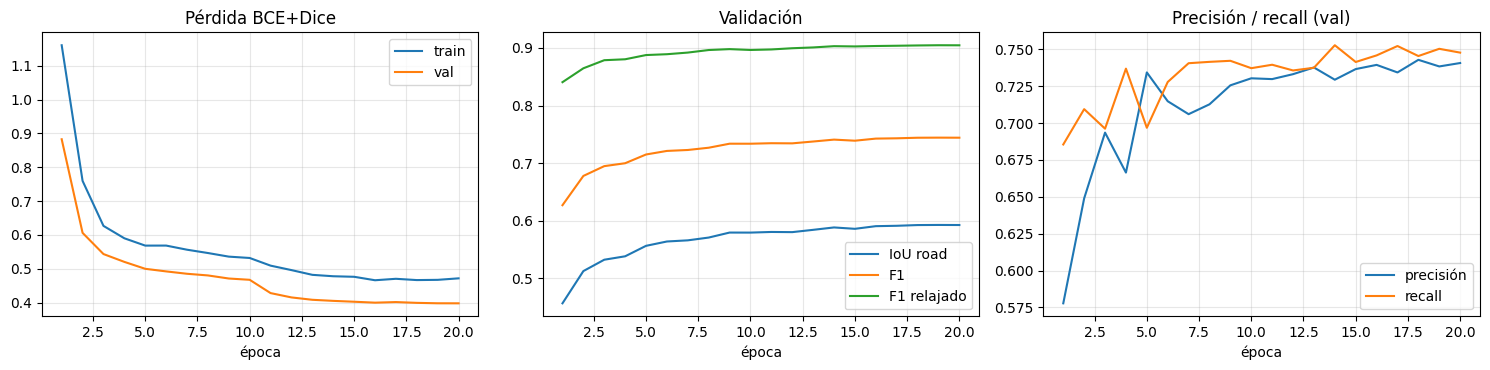

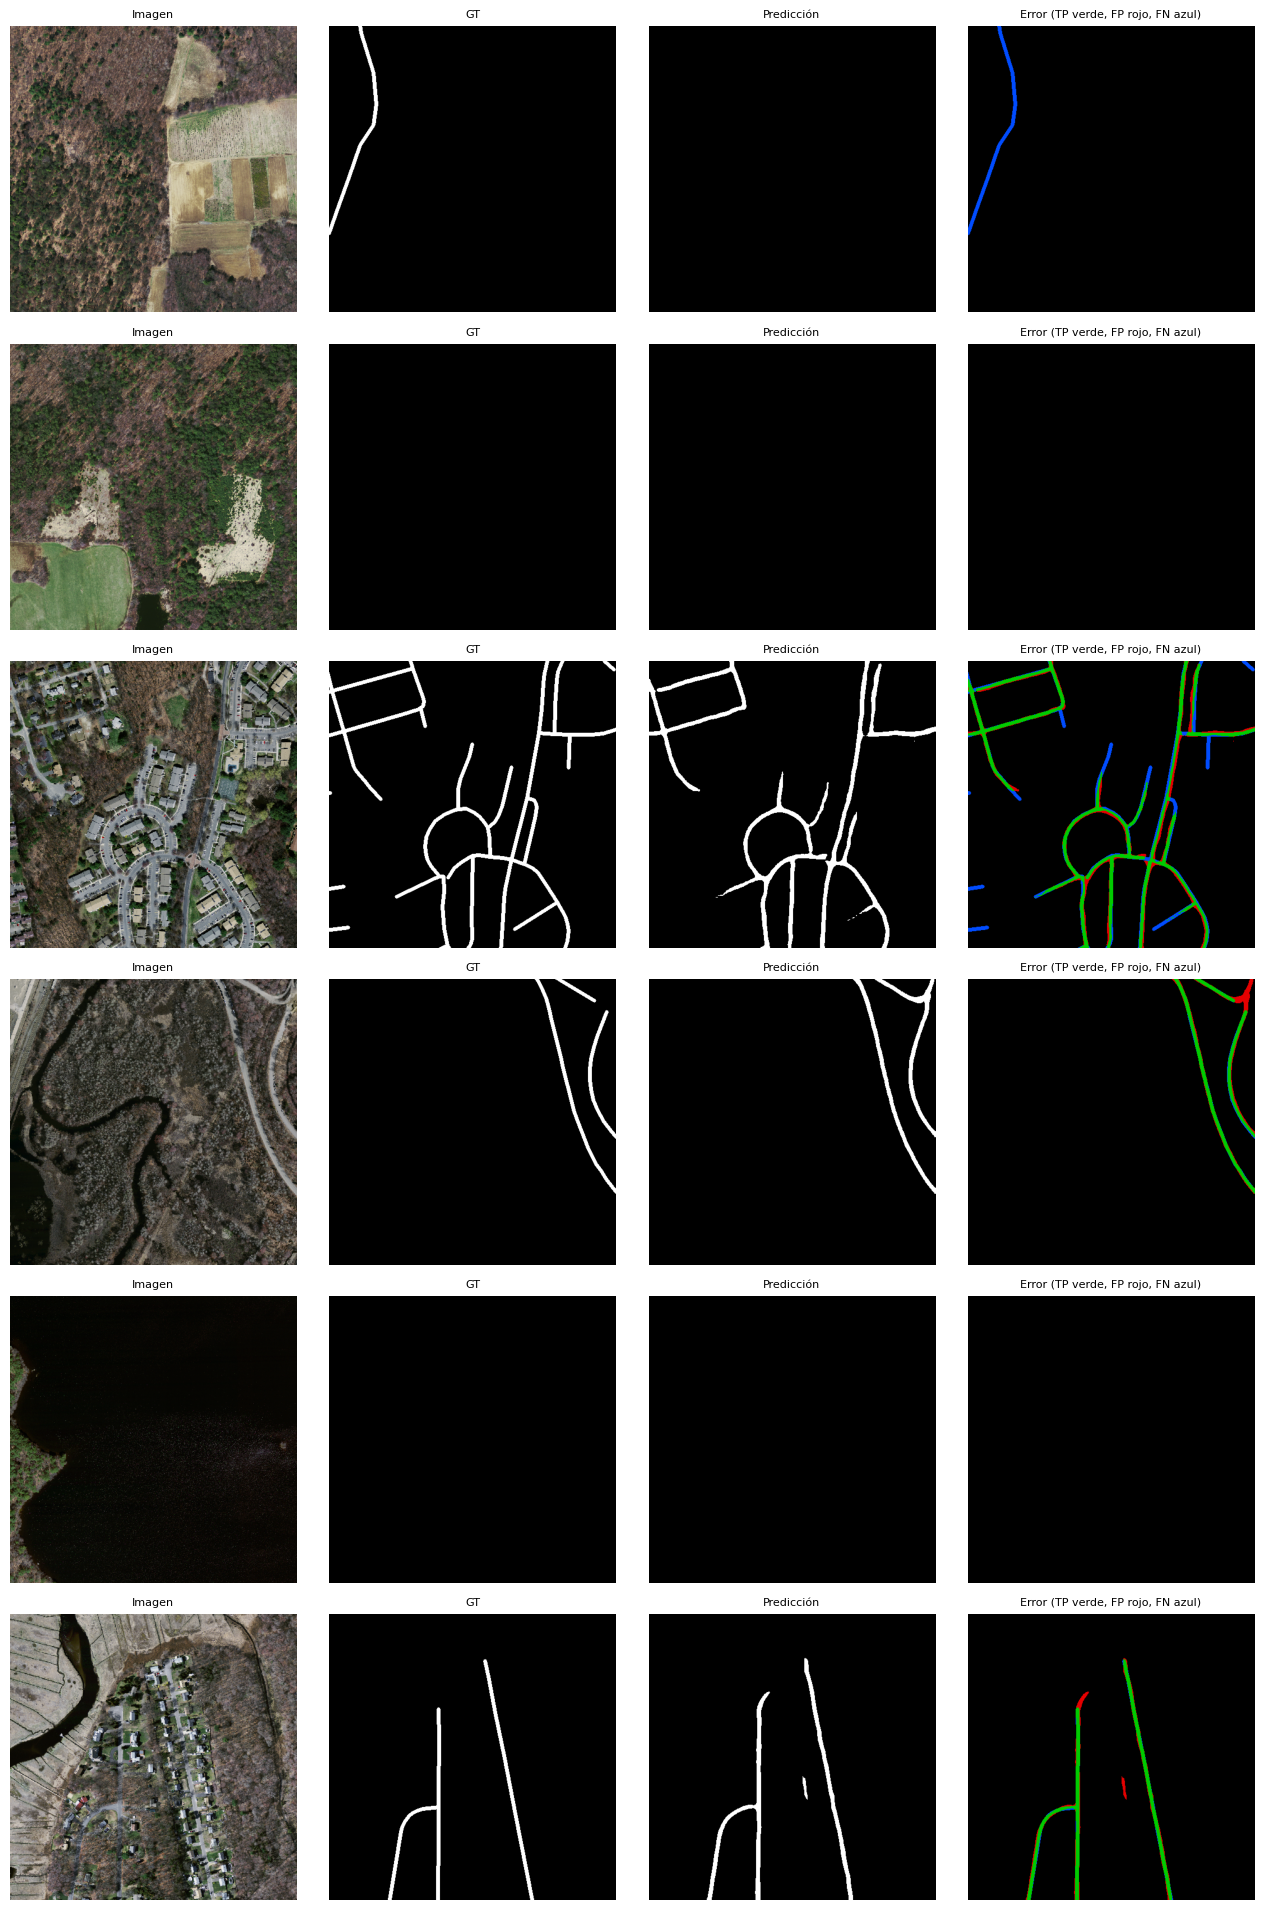

In [18]:
def plot_curves(log, fname):
    df = pd.DataFrame(log)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    axes[0].plot(df.epoch, df.train_loss, label="train"); axes[0].plot(df.epoch, df.val_loss, label="val"); axes[0].set_title("Pérdida BCE+Dice")
    axes[1].plot(df.epoch, df.val_iou_road, label="IoU road"); axes[1].plot(df.epoch, df.val_f1, label="F1"); axes[1].plot(df.epoch, df.val_relaxed_f1, label="F1 relajado")
    axes[1].set_title("Validación")
    axes[2].plot(df.epoch, df.val_precision, label="precisión"); axes[2].plot(df.epoch, df.val_recall, label="recall"); axes[2].set_title("Precisión / recall (val)")
    for ax in axes:
        ax.set_xlabel("época"); ax.grid(alpha=0.3); ax.legend()
    save_fig(fname)


@torch.no_grad()
def qualitative_grid(model, ds, n, fname):
    model.eval()
    idx = np.linspace(0, len(ds) - 1, num=min(n, len(ds)), dtype=int)
    fig, axes = plt.subplots(len(idx), 4, figsize=(13, 3.2 * len(idx)))
    for r, k in enumerate(idx):
        x, y = ds[int(k)]
        with autocast_ctx():
            logit = model(x[None].to(DEVICE))
        pred = (torch.sigmoid(logit.float())[0, 0] > THRESHOLD).cpu().numpy()
        gt = y[0].numpy() > 0.5
        err = np.zeros(gt.shape + (3,), dtype=np.float32)
        err[pred & gt] = (0, 0.8, 0); err[pred & ~gt] = (0.9, 0, 0); err[~pred & gt] = (0, 0.3, 1)
        for ax, im, t, cm in zip(axes[r], [denorm(x), gt, pred, err], ["Imagen", "GT", "Predicción", "Error (TP verde, FP rojo, FN azul)"], [None, "gray", "gray", None]):
            ax.imshow(im, cmap=cm); ax.set_title(t, fontsize=8); ax.axis("off")
    save_fig(fname)


if RUN_TRAINING:
    plot_curves(EPOCH_LOG, f"b2_curves_{DATASET}_{CONDITION}")
    qualitative_grid(model, test_ds, 6, f"b2_qualitative_{DATASET}_{CONDITION}")

## B3. Guardar resultados
Se escribe `results/{DATASET}_{CONDITION}.json` (configuración, parámetros, log por época, mejores métricas de validación, métricas de test, tiempo de entrenamiento y pico de VRAM), el log por época en CSV y el checkpoint en `checkpoints/`. **Enviar el JSON al equipo.**

In [19]:
def save_results():
    cfg_keys = ["DATASET", "CONDITION", "RESNET_WEIGHTS", "DINO_VARIANT", "DINO_INPUT", "N_UNFREEZE", "EPOCHS", "BATCH_SIZE",
                "LR_DECODER", "LR_BACKBONE", "LR_DINO_TAIL", "WEIGHT_DECAY", "AMP", "THRESHOLD", "RELAX_RHO",
                "TRAIN_CROPS_PER_TILE", "MAX_TRAIN_STEPS_PER_EPOCH", "USE_ALIGNED_MASKS", "SEED", "SPLIT_FRACS", "SPLIT_SEED", "SPLIT_TAG"]
    best_row = max(EPOCH_LOG, key=lambda r: r["val_iou_road"])
    out = {"config": {k: globals()[k] for k in cfg_keys}, "params": COUNTS,
           "epochs": EPOCH_LOG, "best_epoch": CK["epoch"],
           "best_val": {k: v for k, v in best_row.items() if k.startswith("val_")},
           "test": TEST_M, "test_loss": TEST_LOSS, "train_time_s": TRAIN_TIME, "peak_vram_mb": PEAK_MB,
           "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu", "torch": torch.__version__,
           "checkpoint": CKPT_PATH}
    path = f"{RESULTS_DIR}/{DATASET}_{CONDITION}_{SPLIT_TAG}.json"
    with open(path, "w") as f:
        json.dump(to_jsonable(out), f, indent=2)
    pd.DataFrame(EPOCH_LOG).to_csv(f"{RESULTS_DIR}/{DATASET}_{CONDITION}_{SPLIT_TAG}_epochs.csv", index=False)
    print("Escrito:", path)
    return out


if RUN_TRAINING:
    RESULT = save_results()
    display(pd.Series(RESULT["test"], name=f"test · {DATASET} · {CONDITION}").to_frame().round(4))

Escrito: /kaggle/working/results/massachusetts_dinov2_partial_resplit.json


,test · massachusetts · dinov2_partial
iou_road,0.5809
iou_bg,0.9707
miou,0.7758
f1,0.7349
precision,0.7293
recall,0.7406
relaxed_precision,0.9346
relaxed_recall,0.8673
relaxed_f1,0.8997
